# Analyse du processus de crédit — carnet de démarche

Ce carnet raconte la démarche pas à pas, sur les données réelles du **BPI Challenge 2012** (van Dongen, B. (2012). BPI Challenge 2012. 4TU.ResearchData. https://doi.org/10.4121/uuid:3926db30-f712-4394-aebc-75976070e91f).

Toutes les fonctions appelées viennent du paquet `cpi` du dépôt : les chiffres sont ceux du rapport interactif et des documents. Prérequis : `make data` (téléchargement vérifié du journal).

**Plan** : 1. données et qualité · 2. parcours réel · 3. temps · 4. allers-retours · 5. abandons · 6. prédiction · 7. business case.

In [1]:
import os
import warnings

os.environ.setdefault("PM4PY_SHOW_PROGRESS_BAR", "False")
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cpi import abandon, discovery, features, kpi, model, rework, simulation
from cpi.cases import build_cases
from cpi.ingest import load_events
from cpi.quality import as_records, run_checks
from cpi.sessions import build_sessions, build_waits

pd.set_option("display.max_colwidth", 90)
INK, MUTED, CONTEXT, BLUE, RED, YELLOW, GREEN = "#111111", "#5b6069", "#c4c8ce", "#1c4da2", "#d72929", "#e3a500", "#007f38"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CONTEXT,
    "axes.grid": True, "grid.color": "#eef0f2", "grid.linewidth": 1, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": MUTED, "font.size": 10,
})

## 1. Données et qualité

Le journal mêle trois sous-processus : les états de la demande (`A_`), de l'offre (`O_`) et les tâches humaines (`W_`), ces dernières avec un cycle de vie *planifiée → démarrée → terminée*. C'est ce cycle de vie qui permet de séparer le temps de travail du temps d'attente.

In [2]:
events = load_events()
sessions, unclosed = build_sessions(events)
waits = build_waits(events)
cases = build_cases(events, sessions)
print(f"{events['case_id'].nunique():,} dossiers · {len(events):,} événements · {events['activity'].nunique()} activités".replace(",", " "))
events.head(8)[["case_id", "activity", "lifecycle", "timestamp", "resource", "amount_req"]]

13 087 dossiers · 262 200 événements · 24 activités


,case_id,activity,lifecycle,timestamp,resource,amount_req
0,173688,A_SUBMITTED,COMPLETE,2011-09-30 22:38:44.546+00:00,112,20000.0
1,173688,A_PARTLYSUBMITTED,COMPLETE,2011-09-30 22:38:44.880+00:00,112,20000.0
2,173688,A_PREACCEPTED,COMPLETE,2011-09-30 22:39:37.906+00:00,112,20000.0
3,173688,W_Completeren aanvraag,SCHEDULE,2011-09-30 22:39:38.875+00:00,112,20000.0
4,173688,W_Completeren aanvraag,START,2011-10-01 09:36:46.437+00:00,<NA>,20000.0
5,173688,A_ACCEPTED,COMPLETE,2011-10-01 09:42:43.308+00:00,10862,20000.0
6,173688,O_SELECTED,COMPLETE,2011-10-01 09:45:09.243+00:00,10862,20000.0
7,173688,A_FINALIZED,COMPLETE,2011-10-01 09:45:09.243+00:00,10862,20000.0


In [3]:
checks, extra = run_checks(events, sessions, unclosed, cases)
pd.DataFrame(as_records(checks))[["label", "status", "value", "treatment"]]

,label,status,value,treatment
0,Volumétrie conforme à la source,ok,13 087 dossiers · 262 200 événements,Arrêt du pipeline en cas d'écart.
1,Champs obligatoires renseignés,ok,aucune valeur manquante,Aucun.
2,Période couverte,info,01/10/2011 → 14/03/2012,Annualisation explicite des volumes (voir le business case).
3,Doublons exacts,ok,aucun doublon,Aucun.
4,Ressource non renseignée,attention,"18 010 événements (6,9 %)",Analyses de charge sur les sessions dont la ressource est connue.
5,Jalons enregistrés au même instant,attention,4 116 dossiers concernés,Réordonnancement canonique des jalons A_/O_ distants de moins d'1 s ; durées calculées...
6,Fin de tâche sans démarrage,attention,1 040 sessions,"Session conservée, durée imputée à la médiane de l'activité."
7,Démarrage sans fin de tâche,info,3 sessions,Sessions ignorées dans le temps de travail.
8,Sessions de plus de 2 h,attention,"477 sessions (0,66 %)",Durée imputée à la médiane de l'activité : 6 801 h de travail retenues (estimation pru...
9,Tâche planifiée jamais exécutée,info,12 planifications,Exclue des analyses de travail.


Deux traitements comptent : les **jalons simultanés** sont remis dans l'ordre métier (sinon 576 variantes artificielles au lieu de 86), et les **sessions restées ouvertes** (plus de deux heures) sont ramenées à la médiane de leur activité. La sensibilité au seuil montre que le choix de deux heures est prudent :

In [4]:
pd.DataFrame(extra["threshold_sensitivity"]).round(3)

,threshold_h,hours,share_imputed
0,0.5,5336.071,0.050
1,1.0,6299.350,0.027
2,2.0,6800.574,0.021
3,4.0,7161.032,0.019
4,8.0,7379.828,0.018


## 2. Le parcours réel (Q1)

Un dossier sur six seulement aboutit à un prêt. La majorité des refus tombe au pré-contrôle automatique, en quelques minutes.

In [5]:
pd.DataFrame(kpi.outcome_summary(cases))

,outcome,label,count,share
0,approved,Approuvée,2246,0.1716
1,declined,Refusée,7635,0.5834
2,cancelled,Annulée,2807,0.2145
3,open,En cours,399,0.0305


In [6]:
v = discovery.variants(events, cases, "milestones", top=8)
print(f"{v['n_variants']} variantes de jalons ; les 5 premières couvrent {v['coverage_top']['5']:.0%} des dossiers")
from cpi.labels import short_label
pd.DataFrame([{"rang": x["rank"], "dossiers": x["count"], "part": round(x["share"], 3),
               "délai médian (j)": x["median_lead_time_d"],
               "parcours": " › ".join(short_label(a) for a in x["activities"])} for x in v["variants"]])

86 variantes de jalons ; les 5 premières couvrent 81% des dossiers


,rang,dossiers,part,délai médian (j),parcours
0,1,5719,0.437,0.00,Soumise › Enregistrée › Refusée
1,2,1537,0.117,13.05,Soumise › Enregistrée › Pré-acceptée › Complétée › Offre sélectionnée › Finalisée › Of...
2,3,1132,0.086,18.94,Soumise › Enregistrée › Pré-acceptée › Complétée › Offre sélectionnée › Finalisée › Of...
3,4,1100,0.084,4.21,Soumise › Enregistrée › Pré-acceptée › Annulée
4,5,1085,0.083,0.67,Soumise › Enregistrée › Pré-acceptée › Refusée
5,6,574,0.044,13.54,Soumise › Enregistrée › Pré-acceptée › Complétée › Offre sélectionnée › Finalisée › Of...
6,7,318,0.024,16.81,Soumise › Enregistrée › Pré-acceptée › Complétée › Offre sélectionnée › Finalisée › Of...
7,8,294,0.022,28.17,Soumise › Enregistrée › Pré-acceptée › Complétée › Offre sélectionnée › Finalisée › Of...


In [7]:
conf = discovery.nominal_conformance(events, cases)
print(f"Prêts approuvés suivant exactement le chemin nominal : {conf['perfect_share']:.0%}")
print(f"... et sans boucle « dossier incomplet » : {conf['first_time_right_share']:.0%}")
print(f"Délai médian : {conf['median_lead_time_nominal_d']} j (nominal) contre {conf['median_lead_time_deviating_d']} j")

Prêts approuvés suivant exactement le chemin nominal : 68%
... et sans boucle « dossier incomplet » : 35%
Délai médian : 11.86 j (nominal) contre 16.09 j


## 3. Combien de temps, et où se perd-il ? (Q2)

On décompose le délai d'un prêt approuvé en phases et on compare le temps écoulé au temps de travail effectif.

In [8]:
ph = kpi.phase_decomposition(cases, sessions)
phases = pd.DataFrame(ph["approved"])
s = ph["approved_summary"]
print(f"Délai moyen {s['mean_lead_time_d']} j pour {s['mean_work_h']:.2f} h de travail : efficacité de flux {s['flow_efficiency_aggregate']:.2%}")
phases[["label", "mean_elapsed_d", "median_elapsed_d", "mean_work_h"]]

Délai moyen 16.66 j pour 1.43 h de travail : efficacité de flux 0.36%


,label,mean_elapsed_d,median_elapsed_d,mean_work_h
0,Pré-contrôle,0.067,0.000,0.008
1,Complétion,0.594,0.126,0.095
2,Retour client,10.835,8.835,0.316
3,Validation,5.163,4.109,1.016


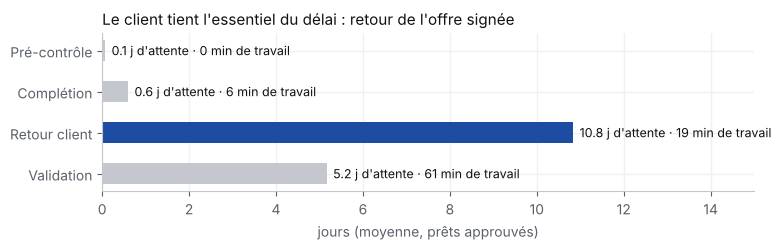

In [9]:
fig, ax = plt.subplots(figsize=(8, 2.6))
colors = [CONTEXT, CONTEXT, BLUE, CONTEXT]
ax.barh(phases["label"][::-1], phases["mean_elapsed_d"][::-1], color=colors[::-1], height=0.5)
for y, (lab, d, w) in enumerate(zip(phases["label"][::-1], phases["mean_elapsed_d"][::-1], phases["mean_work_h"][::-1])):
    ax.text(d + 0.15, y, f"{d:.1f} j d'attente · {w * 60:.0f} min de travail", va="center", color=INK, fontsize=9)
ax.set_xlabel("jours (moyenne, prêts approuvés)")
ax.set_xlim(0, 15)
ax.set_title("Le client tient l'essentiel du délai : retour de l'offre signée", loc="left", color=INK, fontsize=11)
plt.tight_layout()

In [10]:
acts = pd.DataFrame(kpi.activity_times(sessions, waits))
acts[["label", "sessions", "sessions_per_case", "median_session_min", "median_wait_h", "work_h"]]

,label,sessions,sessions_per_case,median_session_min,median_wait_h,work_h
0,Traitement des leads,5898,1.24,1.89,0.71,389.0
1,Complétion de la demande,23967,3.25,2.65,1.76,2164.3
2,Relance des offres,22976,4.59,1.67,0.03,1093.1
3,Validation de la demande,7895,2.46,11.96,25.79,2125.8
4,Relance des dossiers incomplets,11407,6.93,2.08,0.68,1026.0
5,Évaluation fraude,270,2.50,0.15,10.23,2.3


## 4. Le coût des allers-retours (Q3)

In [11]:
annual = kpi.observation_window(events)["annual_factor"]
rw = rework.rework_summary(events, sessions, cases, annual)
inc = rw["incomplete"]
print(f"Boucle « dossier incomplet » : {inc['cases']} dossiers ({inc['share_of_validated']:.0%} des dossiers validés), "
      f"{inc['calls']} appels, {inc['loop_hours_annual']} h par an, délai médian {inc['median_loop_delay_d']} j")
print(f"Offres multiples : {rw['multiple_offers']['share_of_offered']:.0%} des dossiers ayant reçu une offre")
print(f"Relances d'offres : {rw['offer_follow_ups']['calls']} appels, dont {rw['offer_follow_ups']['share_hours_on_cancelled']:.0%} des heures sur des dossiers finalement annulés")

Boucle « dossier incomplet » : 1647 dossiers (51% des dossiers validés), 11407 appels, 3689 h par an, délai médian 2.14 j
Offres multiples : 29% des dossiers ayant reçu une offre
Relances d'offres : 22976 appels, dont 46% des heures sur des dossiers finalement annulés


## 5. Qui abandonne, quand, et pourquoi (Q4)

Le pic à 30 jours trahit la règle d'expiration de l'offre : le client ne l'a jamais renvoyée.

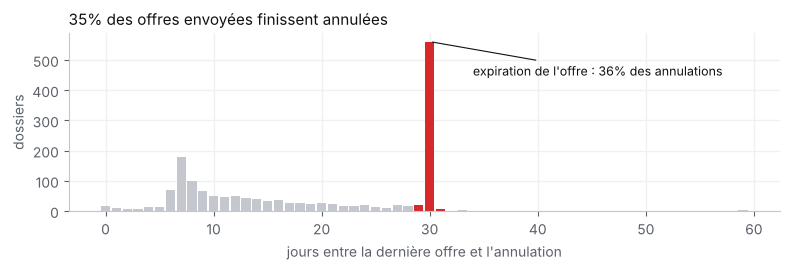

In [12]:
ab = abandon.abandon_summary(cases)
hist = np.array(ab["after_offer"]["hist_days_since_last_offer"])
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(range(len(hist)), hist, width=0.85, color=[RED if 29 <= i <= 31 else CONTEXT for i in range(len(hist))])
ax.annotate(f"expiration de l'offre : {ab['after_offer']['expiry_window_share']:.0%} des annulations",
            xy=(30, hist[30]), xytext=(34, hist.max() * 0.8), color=INK, fontsize=9,
            arrowprops={"arrowstyle": "-", "color": INK, "lw": 0.8})
ax.set_xlabel("jours entre la dernière offre et l'annulation")
ax.set_ylabel("dossiers")
ax.set_title(f"{ab['cancel_rate_after_offer']:.0%} des offres envoyées finissent annulées", loc="left", color=INK, fontsize=11)
plt.tight_layout()

In [13]:
pd.DataFrame(ab["by_delay_to_offer"])

,band,cases,cancelled,cancel_rate,approval_rate
0,< 1 j,3753,1272,0.3389,0.4929
1,1–3 j,693,270,0.3896,0.4473
2,3–7 j,173,71,0.4104,0.3699
3,7–14 j,52,23,0.4423,0.3462
4,≥ 14 j,17,4,0.2353,0.2353


## 6. Peut-on prédire tôt l'abandon ? (Q5)

Point de décision : l'envoi de la première offre. Les variables n'utilisent que le préfixe du dossier. Découpage temporel strict avec zone tampon : apprentissage sur les offres d'octobre et novembre 2011 dont l'issue était connue au 1er janvier 2012, test sur janvier 2012.

Ce n'est **pas** un score d'octroi : il ne servirait qu'à ordonner une file de relance.

In [14]:
ds = features.build_dataset(events, sessions, waits, cases)
split = features.temporal_split(ds, events["timestamp"].max())
print(f"apprentissage {len(split.train)} dossiers ({split.train['label'].mean():.1%} d'abandons) · test {len(split.test)} ({split.test['label'].mean():.1%})")
print("exclus :", split.excluded)
trained = model.fit_models(split)
res = model.evaluate(split, trained)
pd.DataFrame({k: v["metrics"] for k, v in res["models"].items()}).T

apprentissage 1938 dossiers (34.8% d'abandons) · test 950 (35.5%)
exclus : {'train_window_purged_unknown_at_deploy': 43, 'buffer_window': 834, 'test_window_open': 18, 'after_test_window': 1232}


,roc_auc,pr_auc,base_rate,brier,log_loss,mean_predicted,ece
rule,0.5405,0.3873,0.3547,NaN,NaN,NaN,NaN
logreg,0.5395,0.3916,0.3547,0.229,0.6502,0.3683,0.0401
gbm,0.5552,0.4049,0.3547,0.227,0.6462,0.3589,0.0248


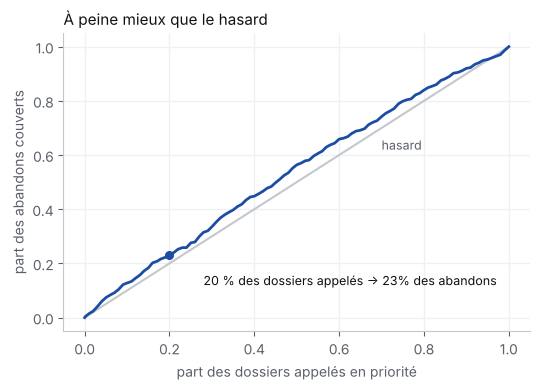

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot([0, 1], [0, 1], color=CONTEXT, lw=1.5)
curve = np.array(res["models"]["gbm"]["gains"]["curve"])
ax.plot(curve[:, 0], curve[:, 1], color=BLUE, lw=2)
at20 = next(a for a in res["models"]["gbm"]["gains"]["at_k"] if a["share"] == 0.2)
ax.scatter([0.2], [at20["recall"]], color=BLUE, zorder=3, s=30)
ax.annotate(f"20 % des dossiers appelés → {at20['recall']:.0%} des abandons", xy=(0.2, at20["recall"]),
            xytext=(0.28, 0.12), fontsize=9, color=INK)
ax.text(0.7, 0.62, "hasard", color=MUTED, fontsize=9)
ax.set_xlabel("part des dossiers appelés en priorité")
ax.set_ylabel("part des abandons couverts")
ax.set_title("À peine mieux que le hasard", loc="left", color=INK, fontsize=11)
plt.tight_layout()

In [16]:
pd.DataFrame(res["acceptance"]["checks"])

,criterion,threshold,value,passed
0,ROC-AUC sur la période de test,≥ 0.65,0.5552,False
1,Lift à 20 % des dossiers,≥ 1.5,1.1570,False
2,Écart de calibration (ECE),≤ 0.05,0.0248,True
3,Stabilité du score (PSI apprentissage → test),< 0.2,0.0763,True


Les seuils, fixés avant l'évaluation, ne sont pas atteints : le modèle est calibré et stable mais ne discrimine pas. Le signal n'est pas dans les traces du processus ; le pilote de relance utilisera une règle simple.

## 7. Opportunités IA et business case (Q6)

Rejeu contrefactuel des dossiers réels (boucles évitées tirées au sort, heures et délais réels retirés) et Monte Carlo sur les hypothèses explicites de `config/hypotheses.yaml`.

In [17]:
loops = rework.incomplete_loops(events, sessions, cases)
median_call = float(sessions.loc[sessions["activity"] == "W_Nabellen offertes", "dur_s"].median() / 60)
bc = simulation.run(cases, loops, annual, at20["recall"], median_call)
rows = []
for k, o in bc["opportunities"].items():
    mc = o["monte_carlo"]
    rows.append({"opportunité": o["title"], "gain annuel P50 (k€)": round(mc["annual_benefit"]["p50"] / 1000),
                 "VAN P10 (k€)": round(mc["npv"]["p10"] / 1000), "VAN P50 (k€)": round(mc["npv"]["p50"] / 1000),
                 "VAN P90 (k€)": round(mc["npv"]["p90"] / 1000), "P(VAN > 0)": mc["prob_npv_positive"],
                 "retour (mois)": o["central"]["payback_month"]})
pd.DataFrame(rows)

,opportunité,gain annuel P50 (k€),VAN P10 (k€),VAN P50 (k€),VAN P90 (k€),P(VAN > 0),retour (mois)
0,Contrôle automatique de complétude à la soumission,105,-4,48,108,0.8774,24.0
1,Priorisation des relances d'offres par score d'abandon,48,-45,1,68,0.5148,36.0
2,Pré-analyse assistée des dossiers à valider,53,-132,-89,-45,0.0036,NaN


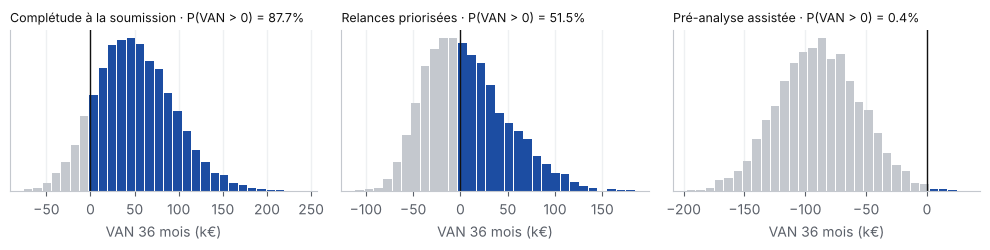

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=False)
for ax, (k, o) in zip(axes, bc["opportunities"].items()):
    h = o["monte_carlo"]["npv_hist"]
    edges, counts = np.array(h["edges"]) / 1000, np.array(h["counts"])
    mids = (edges[:-1] + edges[1:]) / 2
    ax.bar(mids, counts, width=(edges[1] - edges[0]) * 0.9, color=[BLUE if m >= 0 else CONTEXT for m in mids])
    ax.axvline(0, color=INK, lw=1)
    ax.set_title(f"{o['short']} · P(VAN > 0) = {o['monte_carlo']['prob_npv_positive']:.1%}", loc="left", fontsize=9, color=INK)
    ax.set_xlabel("VAN 36 mois (k€)")
    ax.set_yticks([])
plt.tight_layout()

## Conclusions

- Le délai se perd en **attente** (client, file de validation), pas en travail : l'efficacité de flux est inférieure à 1 %.
- La boucle « dossier incomplet » touche un dossier validé sur deux : c'est le levier le plus solide, d'où le **contrôle de complétude au dépôt** (VAN positive dans la grande majorité des scénarios).
- Les traces du processus ne permettent pas de prédire l'abandon : la **relance priorisée** se teste d'abord en A/B sur une règle simple.
- La **pré-analyse assistée** ne se justifie pas par la seule productivité à ce volume ; elle est aussi la plus exposée à l'AI Act (annexe III, point 5 b).

Détails : `docs/02-analyse-as-is.md`, `docs/05-business-case.md`, `docs/06-conformite-ia-rgpd.md`.